<a href="https://colab.research.google.com/github/arilramadhan12-cyber/-Brightness-adjustment/blob/main/Brightness_adjustment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1.Membaca dan Menampilkan Citra Asli

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Ditemukan: ['/content/drive/MyDrive/Ariel rahmadhan (24260041)/Foto bareng di stadion.jpeg']
Shape: (1200, 900, 3) | dtype: uint8


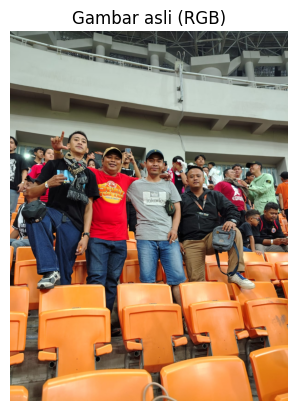

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, glob
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

cari = glob.glob('/content/drive/MyDrive/Ariel rahmadhan (24260041)/Foto bareng di stadion.jpeg', recursive=True)
print('Ditemukan:', cari)

if cari:
    nama_file = cari[0]
else:
    nama_file = 'images/kucing.jpg'   # cadangan kalau dijalankan dari repo

img = Image.open(nama_file).convert('RGB')
img.thumbnail((1200, 1200))
arr = np.array(img)
print('Shape:', arr.shape, '| dtype:', arr.dtype)
plt.imshow(arr); plt.title('Gambar asli (RGB)'); plt.axis('off'); plt.show()

# 2.Konversi Citra RGB ke Grayscale

Shape gray : (1200, 900)
Min / Max  : 0 / 255


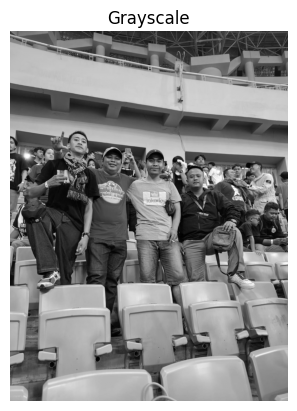

In [ ]:
R = arr[:, :, 0].astype(float)
G = arr[:, :, 1].astype(float)
B = arr[:, :, 2].astype(float)

gray = (0.299*R + 0.587*G + 0.114*B).astype(np.uint8)

print('Shape gray :', gray.shape)
print('Min / Max  :', gray.min(), '/', gray.max())
plt.imshow(gray, cmap='gray', vmin=0, vmax=255); plt.title('Grayscale'); plt.axis('off'); plt.show()

# 3.Peningkatan Kontras dengan Contrast Stretching

Sebelum: min = 0 , max = 255
Sesudah: min = 0 , max = 255


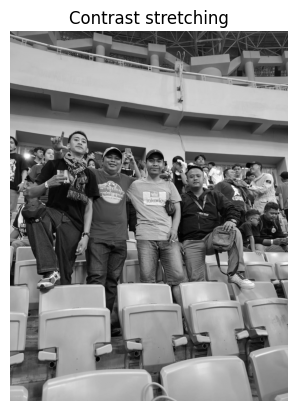

In [ ]:
mn, mx = int(gray.min()), int(gray.max())

if mx == mn:
    stretch = gray.copy()
else:
    stretch = ((gray.astype(float) - mn) / (mx - mn) * 255).astype(np.uint8)

print('Sebelum: min =', mn, ', max =', mx)
print('Sesudah: min =', stretch.min(), ', max =', stretch.max())
plt.imshow(stretch, cmap='gray', vmin=0, vmax=255); plt.title('Contrast stretching'); plt.axis('off'); plt.show()

# 4.Perbandingan Citra dan Histogram Sebelum dan Sesudah Contrast Stretching

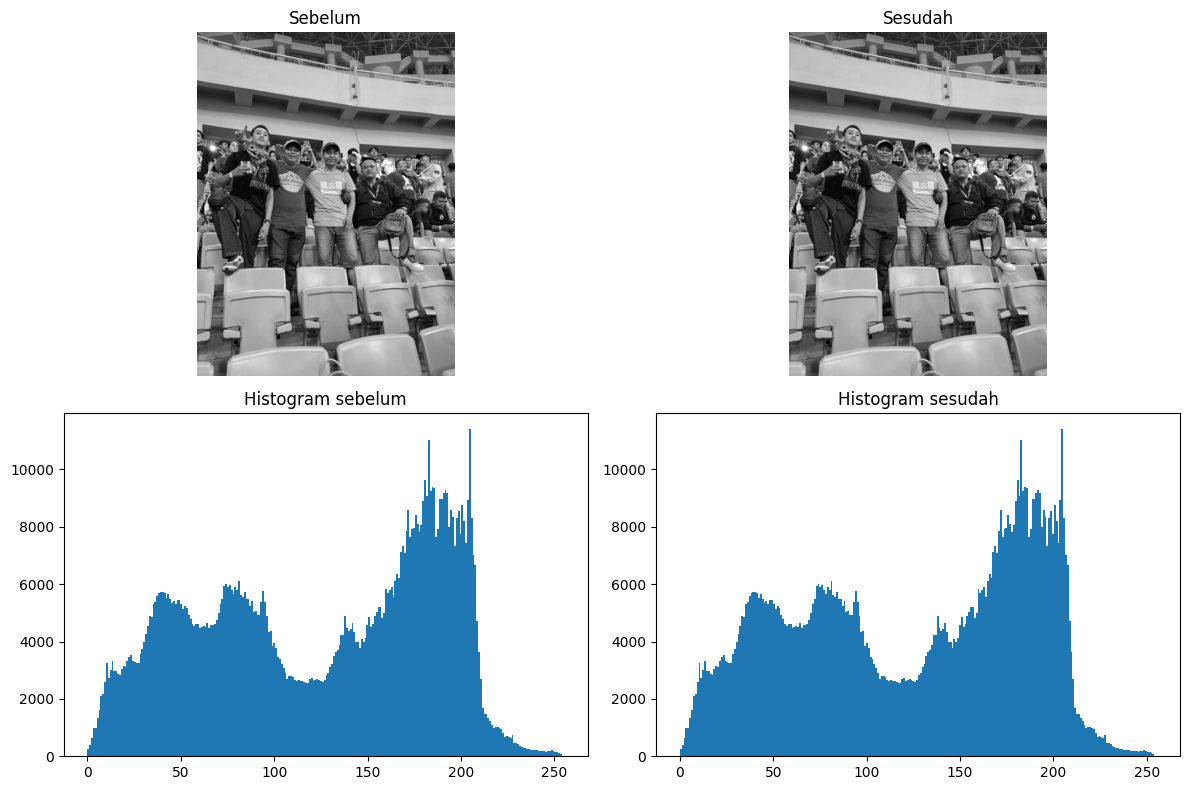

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
ax[0, 0].imshow(gray, cmap='gray', vmin=0, vmax=255); ax[0, 0].set_title('Sebelum'); ax[0, 0].axis('off')
ax[0, 1].imshow(stretch, cmap='gray', vmin=0, vmax=255); ax[0, 1].set_title('Sesudah'); ax[0, 1].axis('off')
ax[1, 0].hist(gray.ravel(), bins=256, range=(0, 255)); ax[1, 0].set_title('Histogram sebelum')
ax[1, 1].hist(stretch.ravel(), bins=256, range=(0, 255)); ax[1, 1].set_title('Histogram sesudah')
plt.tight_layout(); plt.show()

# 5.Demonstrasi Contrast Stretching pada Citra Pucat (Rentang Intensitas Sempit)

Gambar pucat   : min = 80 , max = 182
Setelah stretch: min = 0 , max = 255


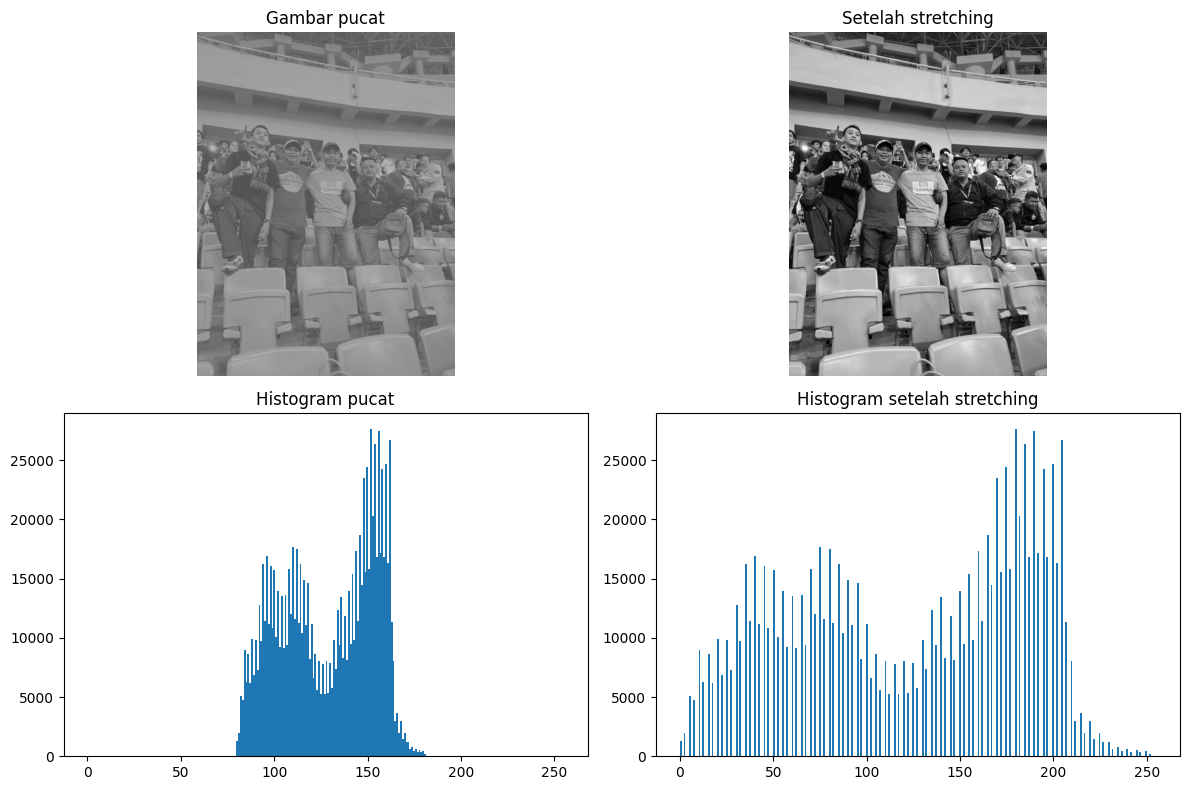

In [ ]:
# Demo: bikin gambar pucat (rentang sempit), lalu stretching
pucat = (gray.astype(float) * 0.4 + 80).astype(np.uint8)
mn2, mx2 = int(pucat.min()), int(pucat.max())
pucat_stretch = ((pucat.astype(float) - mn2) / (mx2 - mn2) * 255).astype(np.uint8)

print('Gambar pucat   : min =', mn2, ', max =', mx2)
print('Setelah stretch: min =', pucat_stretch.min(), ', max =', pucat_stretch.max())

fig, ax = plt.subplots(2, 2, figsize=(12, 8))
ax[0, 0].imshow(pucat, cmap='gray', vmin=0, vmax=255); ax[0, 0].set_title('Gambar pucat'); ax[0, 0].axis('off')
ax[0, 1].imshow(pucat_stretch, cmap='gray', vmin=0, vmax=255); ax[0, 1].set_title('Setelah stretching'); ax[0, 1].axis('off')
ax[1, 0].hist(pucat.ravel(), bins=256, range=(0, 255)); ax[1, 0].set_title('Histogram pucat')
ax[1, 1].hist(pucat_stretch.ravel(), bins=256, range=(0, 255)); ax[1, 1].set_title('Histogram setelah stretching')
plt.tight_layout(); plt.show()

# 6.Verifikasi Perhitungan Contrast Stretching pada Piksel Tertentu

In [ ]:
for (y, x) in [(0, 0), (10, 10), (50, 50)]:
    f = int(gray[y, x])
    manual = int((f - mn) / (mx - mn) * 255) if mx != mn else f
    print(f'Piksel ({y},{x}): asli = {f:3d} | hasil kode = {stretch[y, x]:3d} | hitung manual = {manual:3d}')

Piksel (0,0): asli = 100 | hasil kode = 100 | hitung manual = 100
Piksel (10,10): asli =  58 | hasil kode =  58 | hitung manual =  58
Piksel (50,50): asli = 183 | hasil kode = 183 | hitung manual = 183
